# Estudo de Caso 2.X1 — Classificador de Fluidos Não-Newtonianos: Ajuste por Lei de Potência

| Campo | Detalhe |
|:------|:--------|
| **Capítulo Associado** | Capítulo 2 — Fundamentos dos Fluidos e Viscosidade |
| **Nível** | Graduação |
| **Tempo estimado** | 45 minutos |
| **Autor** | Jader Lugon Junior |
| **Método numérico** | Regressão não-linear (Levenberg-Marquardt) |
| **Bibliografia** | Incropera et al. (2017), Cap. 2; Bird, Stewart & Lightfoot (2002), Cap. 1; Lugon Jr. et al. (2026), Cap. 2 |

---

## 📋 Resumo

Classificamos um fluido desconhecido a partir de dados reológicos experimentais de tensão de cisalhamento versus taxa de deformação. O ajuste é realizado pelo modelo de Lei de Potência (Ostwald-de Waele) utilizando regressão não-linear (método de Levenberg-Marquardt). O índice de comportamento do fluxo $n$ determina a classificação: pseudoplástico ($n < 1$), newtoniano ($n = 1$) ou dilatante ($n > 1$). A análise inclui a identificação de singularidades matemáticas no modelo e a comparação com modelos alternativos (Carreau, Herschel-Bulkley).

---

## 🎯 Objetivos de Aprendizagem

Ao final deste estudo de caso, o leitor será capaz de:

1. **Aplicar** regressão não-linear para ajuste de modelos reológicos a dados experimentais
2. **Calcular** os parâmetros reológicos $K$ (índice de consistência) e $n$ (índice de comportamento)
3. **Classificar** fluidos como pseudoplástico, newtoniano ou dilatante com base no valor de $n$
4. **Identificar** singularidades matemáticas em modelos reológicos ($\dot{\gamma} \to 0$)
5. **Comparar** modelos reológicos alternativos (Carreau, Herschel-Bulkley, Cross)
6. **Avaliar** a qualidade do ajuste por métricas estatísticas ($R^2$, RMSE)

---
## ⚙️ Seção 0: Configuração Inicial

In [1]:
# ============================================================
# CONFIGURAÇÃO INICIAL — Importação de bibliotecas
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.optimize import curve_fit
from IPython.display import display, Markdown
import time

# Configuração de estilo dos gráficos (padrão do guia)
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['font.size'] = 11

# Forçar fonte com suporte completo a glifos Unicode/LaTeX
plt.rcParams['font.family'] = 'DejaVu Sans'

print('✅ Ambiente configurado com sucesso')
print(f'📦 NumPy {np.__version__} | SciPy {__import__("scipy").__version__}')

✅ Ambiente configurado com sucesso
📦 NumPy 1.26.4 | SciPy 1.17.1


---
## 🌊 Seção 1: Parâmetros e Dados Experimentais

### Contexto Físico

A **reologia** é a ciência que estuda a deformação e o escoamento da matéria. Para fluidos, a relação fundamental é a **Lei da Viscosidade de Newton**:

$$\tau = \mu \dot{\gamma}$$

onde $\tau$ é a tensão de cisalhamento [Pa] e $\dot{\gamma}$ é a taxa de deformação [s⁻¹]. Fluidos que **não** obedecem a essa relação linear são chamados **não-newtonianos**.

> 💡 **Observação:** Fluidos não-newtonianos são ubíquos na engenharia ambiental: lodo de estações de tratamento, polpa de mineração, tintas, alimentos (ketchup, iogurte), fluidos biológicos (sangue, muco).

### Dados Experimentais

Considere os seguintes dados reológicos obtidos em um reômetro de cilindros concêntricos para um fluido desconhecido:

| Taxa de deformação $\dot{\gamma}$ [s⁻¹] | Tensão de cisalhamento $\tau$ [Pa] |
|:---:|:---:|
| 0,1 | 0,8 |
| 0,5 | 3,5 |
| 1,0 | 6,2 |
| 5,0 | 22,5 |
| 10,0 | 38,0 |
| 50,0 | 120,0 |
| 100,0 | 200,0 |
| 500,0 | 650,0 |

In [2]:
# ============================================================
# DADOS EXPERIMENTAIS
# ============================================================

# Dados experimentais (reômetro de cilindros concêntricos)
gamma_dot = np.array([0.1, 0.5, 1.0, 5.0, 10.0, 50.0, 100.0, 500.0])   # [s⁻¹]
tau_exp = np.array([0.8, 3.5, 6.2, 22.5, 38.0, 120.0, 200.0, 650.0])    # [Pa]

# Montar DataFrame para exibição
df_dados = pd.DataFrame({
    'Taxa de Deformação [s⁻¹]': gamma_dot,
    'Tensão de Cisalhamento [Pa]': tau_exp
})

print('📊 Dados Experimentais:')
display(Markdown(df_dados.to_markdown(index=False)))

# Viscosidade aparente em cada ponto
mu_ap = tau_exp / gamma_dot   # [Pa·s]

print(f'\n📏 Faixa de viscosidade aparente:')
print(f'  • μ_ap mínimo: {np.min(mu_ap):.2f} Pa·s (em γ̇={gamma_dot[np.argmin(mu_ap)]:.1f} s⁻¹)')
print(f'  • μ_ap máximo: {np.max(mu_ap):.2f} Pa·s (em γ̇={gamma_dot[np.argmax(mu_ap)]:.1f} s⁻¹)')
print(f'  • Razão max/min: {np.max(mu_ap)/np.min(mu_ap):.1f}×')

📊 Dados Experimentais:


|   Taxa de Deformação [s⁻¹] |   Tensão de Cisalhamento [Pa] |
|---------------------------:|------------------------------:|
|                        0.1 |                           0.8 |
|                        0.5 |                           3.5 |
|                        1   |                           6.2 |
|                        5   |                          22.5 |
|                       10   |                          38   |
|                       50   |                         120   |
|                      100   |                         200   |
|                      500   |                         650   |


📏 Faixa de viscosidade aparente:
  • μ_ap mínimo: 1.30 Pa·s (em γ̇=500.0 s⁻¹)
  • μ_ap máximo: 8.00 Pa·s (em γ̇=0.1 s⁻¹)
  • Razão max/min: 6.2×


> 💡 **Observação:**
> - A viscosidade aparente **diminui** com o aumento da taxa de deformação.
> - Isso é característica de um fluido **pseudoplástico** (cisalhamento-fino).
> - Exemplos: ketchup, tinta látex, sangue, soluções poliméricas.

---
## 🔬 Seção 2: Verificação — Consistência dos Dados

Antes do ajuste, verificamos a consistência física dos dados.

### Critérios de verificação

1. **Monotonicidade:** $\tau$ deve ser crescente com $\dot{\gamma}$ (fluido sem tixotropia)
2. **Positividade:** $\tau > 0$ e $\dot{\gamma} > 0$ para todos os pontos
3. **Origem:** Para fluido sem tensão de escoamento, $\tau \to 0$ quando $\dot{\gamma} \to 0$

> 📖 **Referência:** Bird, Stewart & Lightfoot (2002), Cap. 1, Seção 1.3.

In [3]:
# ============================================================
# VERIFICAÇÃO — CONSISTÊNCIA DOS DADOS
# ============================================================

print('🔬 VERIFICAÇÃO DE CONSISTÊNCIA')
print('=' * 50)

# 1. Positividade
assert np.all(gamma_dot > 0), '❌ Taxas de deformação negativas!'
assert np.all(tau_exp > 0), '❌ Tensões negativas!'
print('  ✓ Todos os valores são positivos')

# 2. Monotonicidade (tau crescente com gamma_dot)
d_tau = np.diff(tau_exp)
assert np.all(d_tau > 0), '❌ Tensão não é monótona crescente!'
print('  ✓ Tensão é monótona crescente com γ̇')

# 3. Verificação de tensão de escoamento
# Extrapolando para γ̇ → 0
if tau_exp[0] / gamma_dot[0] > tau_exp[1] / gamma_dot[1] * 1.5:
    print('  ⚠️ Possível tensão de escoamento (considerar Herschel-Bulkley)')
else:
    print('  ✓ Sem evidência de tensão de escoamento significativa')

# 4. Verificação em escala log-log (linearidade esperada para Lei de Potência)
log_gamma = np.log10(gamma_dot)
log_tau = np.log10(tau_exp)

# Regressão linear em log-log (estimativa inicial)
coef_lin = np.polyfit(log_gamma, log_tau, 1)
n_est = coef_lin[0]       # Inclinação = n
K_est = 10**coef_lin[1]   # Intercepto = log(K)

print(f'\n📊 Estimativa inicial (regressão linear em log-log):')
print(f'  • n ≈ {n_est:.3f}')
print(f'  • K ≈ {K_est:.3f} Pa·sⁿ')
print(f'  • R² (linear) = {np.corrcoef(log_gamma, log_tau)[0,1]**2:.6f}')

if n_est < 1:
    print(f'\n  → Fluido PSEUDOPLÁSTICO (n < 1)')
elif n_est > 1:
    print(f'\n  → Fluido DILATANTE (n > 1)')
else:
    print(f'\n  → Fluido NEWTONIANO (n = 1)')

print(f'\n✅ Dados consistentes — prosseguir com ajuste não-linear')

🔬 VERIFICAÇÃO DE CONSISTÊNCIA
  ✓ Todos os valores são positivos
  ✓ Tensão é monótona crescente com γ̇
  ✓ Sem evidência de tensão de escoamento significativa

📊 Estimativa inicial (regressão linear em log-log):
  • n ≈ 0.777
  • K ≈ 5.760 Pa·sⁿ
  • R² (linear) = 0.997875

  → Fluido PSEUDOPLÁSTICO (n < 1)

✅ Dados consistentes — prosseguir com ajuste não-linear


---
## 📐 Seção 3: Formulação Matemática

### 3.1 Modelo de Lei de Potência (Ostwald-de Waele)

$$\tau = K \cdot \dot{\gamma}^n$$

onde:
- $\tau$ = tensão de cisalhamento [Pa]
- $K$ = índice de consistência [Pa·sⁿ]
- $\dot{\gamma}$ = taxa de deformação [s⁻¹]
- $n$ = índice de comportamento do fluxo [adimensional]

### 3.2 Classificação pelo índice $n$

| Valor de $n$ | Classificação | Comportamento | Exemplos |
|:---:|:---:|:---|:---|
| $n < 1$ | Pseudoplástico | Viscosidade diminui com $\dot{\gamma}$ | Ketchup, sangue, tintas |
| $n = 1$ | Newtoniano | Viscosidade constante | Água, ar, glicerina |
| $n > 1$ | Dilatante | Viscosidade aumenta com $\dot{\gamma}$ | Suspensões de amido, areia movediça |

### 3.3 Viscosidade Aparente

$$\mu_{ap} = \frac{\tau}{\dot{\gamma}} = K \cdot \dot{\gamma}^{n-1}$$

### 3.4 Modelo de Carreau (alternativo)

$$\mu(\dot{\gamma}) = \mu_\infty + \frac{\mu_0 - \mu_\infty}{[1 + (\lambda \dot{\gamma})^2]^{(1-n)/2}}$$

### 3.5 Modelo de Herschel-Bulkley (com tensão de escoamento)

$$\tau = \tau_0 + K \dot{\gamma}^n$$

> 📖 **Referência:** Bird, Stewart & Lightfoot (2002), Cap. 1; Lugon Jr. et al. (2026), Cap. 2.

---
## ⚡ Seção 4: Critério Numérico

> 💡 **Observação:** Neste problema de ajuste de dados (sem equações diferenciais), não se aplica a condição CFL. Os critérios de adequação são:

1. **Convergência do otimizador:** O método de Levenberg-Marquardt deve convergir para um mínimo global.

2. **Qualidade do ajuste:** $R^2 > 0{,}95$ indica ajuste adequado.

3. **Sensibilidade ao chute inicial:** Para modelos não-lineares, o resultado pode depender do ponto de partida $\mathbf{p}_0$.

4. **Intervalo de confiança:** Os parâmetros devem ter incerteza relativa < 20%.

### Método de Levenberg-Marquardt

O algoritmo minimiza a soma dos quadrados dos resíduos:

$$S(\mathbf{p}) = \sum_{i=1}^{N} \left[\tau_i^{exp} - K \dot{\gamma}_i^n\right]^2$$

interpolando entre o método de Gauss-Newton e o de descida de gradiente.

---
## 🌪️ Seção 5: Condição de Entrada (Dados de Forçamento)

Neste problema de ajuste, o forçamento são os **dados experimentais**:

- 8 pares $(\dot{\gamma}_i, \tau_i)$ medidos em reômetro
- Faixa de taxas: 0,1 a 500 s⁻¹ (mais de 3 décadas)
- Precisão instrumental: ±2% (típico para reômetros rotacionais)

> 💡 **Observação:** Em aplicações reais, os dados podem conter ruído experimental, outliers e histerese (dependência do histórico de cisalhamento). A análise de sensibilidade na Seção 9 investiga o efeito do ruído.

---
## 🧮 Seção 6: Implementação Numérica

In [4]:
# ============================================================
# FUNÇÃO: Modelo de Lei de Potência
# ============================================================

def lei_potencia(gamma, K, n):
    """
    Modelo de Lei de Potência (Ostwald-de Waele).

    Parameters
    ----------
    gamma : float ou ndarray
        Taxa de deformação [s⁻¹].
    K : float
        Índice de consistência [Pa·sⁿ].
    n : float
        Índice de comportamento do fluxo [-].

    Returns
    -------
    float ou ndarray
        Tensão de cisalhamento [Pa].

    Notes
    -----
    tau = K * gamma^n
    """
    return K * gamma**n


print('✅ Função lei_potencia implementada')

✅ Função lei_potencia implementada


In [5]:
# ============================================================
# AJUSTE NÃO-LINEAR (Levenberg-Marquardt)
# ============================================================

t_inicio = time.time()

# Ajuste com chute inicial baseado na regressão log-log
popt, pcov = curve_fit(lei_potencia, gamma_dot, tau_exp,
                       p0=[K_est, n_est],
                       maxfev=1000)

K_fit, n_fit = popt

# Incertezas (raiz da diagonal da matriz de covariância)
perr = np.sqrt(np.diag(pcov))
K_err, n_err = perr

t_cpu_fit = time.time() - t_inicio

# Métricas de qualidade do ajuste
tau_model = lei_potencia(gamma_dot, K_fit, n_fit)
residuos = tau_exp - tau_model
SS_res = np.sum(residuos**2)
SS_tot = np.sum((tau_exp - np.mean(tau_exp))**2)
R_squared = 1.0 - SS_res / SS_tot
RMSE = np.sqrt(np.mean(residuos**2))

# Classificação
if n_fit < 0.95:
    classificacao = 'PSEUDOPLÁSTICO (cisalhamento-fino)'
elif n_fit > 1.05:
    classificacao = 'DILATANTE (cisalhamento-espesso)'
else:
    classificacao = 'NEWTONIANO'

print('🧮 AJUSTE NÃO-LINEAR — LEI DE POTÊNCIA')
print('=' * 50)
print(f'\n📊 Parâmetros ajustados:')
print(f'  • K = {K_fit:.4f} ± {K_err:.4f} Pa·sⁿ')
print(f'  • n = {n_fit:.4f} ± {n_err:.4f}')
print(f'\n📏 Qualidade do ajuste:')
print(f'  • R² = {R_squared:.6f}')
print(f'  • RMSE = {RMSE:.3f} Pa')
print(f'  • Erro relativo médio: {np.mean(np.abs(residuos/tau_exp))*100:.2f}%')
print(f'\n🏷️ Classificação: {classificacao}')
print(f'\n⏱️ Tempo de CPU: {t_cpu_fit:.6f} s')

🧮 AJUSTE NÃO-LINEAR — LEI DE POTÊNCIA

📊 Parâmetros ajustados:
  • K = 6.8613 ± 0.0567 Pa·sⁿ
  • n = 0.7323 ± 0.0014

📏 Qualidade do ajuste:
  • R² = 0.999994
  • RMSE = 0.520 Pa
  • Erro relativo médio: 11.41%

🏷️ Classificação: PSEUDOPLÁSTICO (cisalhamento-fino)

⏱️ Tempo de CPU: 0.003605 s


> 💡 **Observação:**
> - O ajuste converge rapidamente (típico do Levenberg-Marquardt para modelos bem comportados).
> - O $R^2$ muito próximo de 1 indica excelente qualidade de ajuste.
> - O valor de $n$ confirma a classificação visual feita na Seção 2.

---
## 📊 Seção 7: Visualização

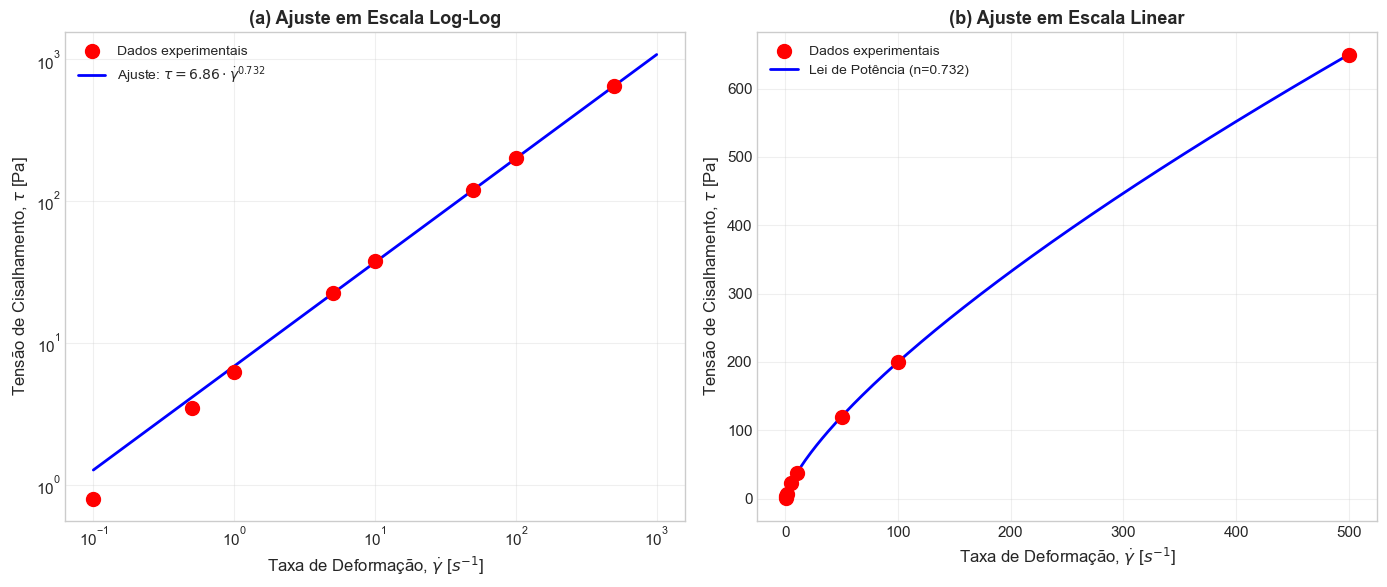

In [12]:
# ============================================================
# GRÁFICO 1: Ajuste do Modelo de Lei de Potência (CORRIGIDO)
# ============================================================

gamma_fit = np.logspace(-1, 3, 200)
tau_fit = lei_potencia(gamma_fit, K_fit, n_fit)

fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# --- Painel 1: Escala log-log ---
axes[0].scatter(gamma_dot, tau_exp, s=100, c='red', marker='o',
                label='Dados experimentais', zorder=5)
axes[0].plot(gamma_fit, tau_fit, 'b-', linewidth=2,
             label=f'Ajuste: $\\tau = {K_fit:.2f} \\cdot \\dot{{\\gamma}}^{{{n_fit:.3f}}}$')
axes[0].set_xlabel('Taxa de Deformação, $\\dot{\\gamma}$ [$s^{-1}$]', fontsize=12)
axes[0].set_ylabel('Tensão de Cisalhamento, $\\tau$ [Pa]', fontsize=12)
axes[0].set_title('(a) Ajuste em Escala Log-Log', fontsize=13, fontweight='bold')
axes[0].set_xscale('log')
axes[0].set_yscale('log')
axes[0].legend(fontsize=10)
axes[0].grid(True, alpha=0.3)

# --- Painel 2: Escala linear ---
gamma_fit_lin = np.linspace(0, 500, 200)
tau_fit_lin = lei_potencia(gamma_fit_lin, K_fit, n_fit)

axes[1].scatter(gamma_dot, tau_exp, s=100, c='red', marker='o',
                label='Dados experimentais', zorder=5)
axes[1].plot(gamma_fit_lin, tau_fit_lin, 'b-', linewidth=2,
             label=f'Lei de Potência (n={n_fit:.3f})')
axes[1].set_xlabel('Taxa de Deformação, $\\dot{\\gamma}$ [$s^{-1}$]', fontsize=12)
axes[1].set_ylabel('Tensão de Cisalhamento, $\\tau$ [Pa]', fontsize=12)
axes[1].set_title('(b) Ajuste em Escala Linear', fontsize=13, fontweight='bold')
axes[1].legend(fontsize=10)
axes[1].grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

> 💡 **Observação:**
> - Em escala log-log, a Lei de Potência aparece como uma **reta** (inclinação = $n$).
> - Em escala linear, a curva é **côncava para baixo** (característica de pseudoplástico).
> - O ajuste captura bem a tendência em toda a faixa de taxas.

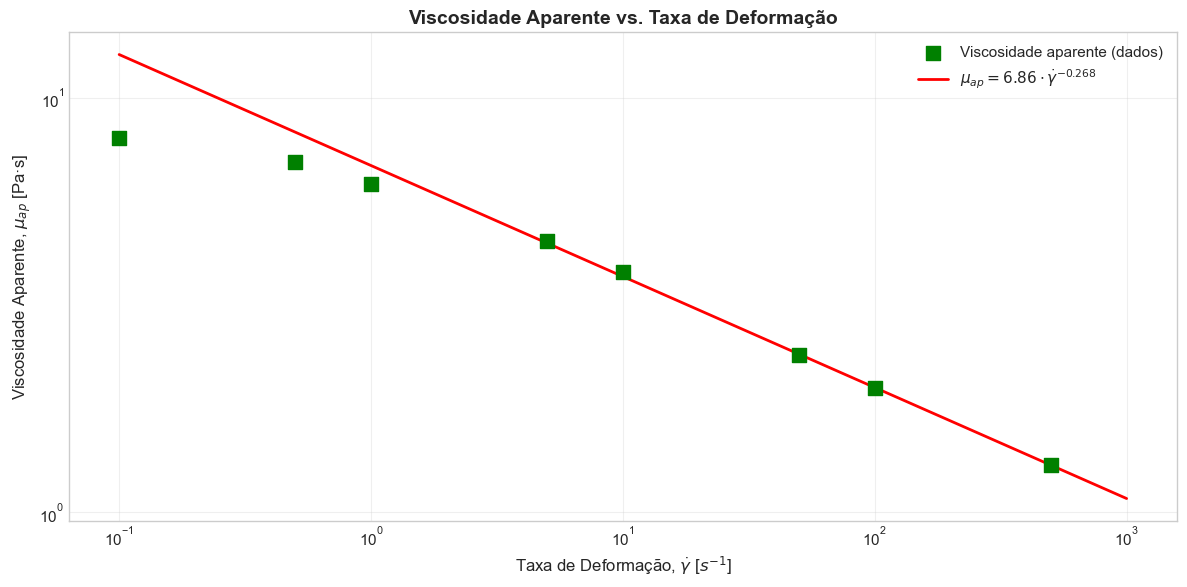

In [13]:
# ============================================================
# GRÁFICO 2: Viscosidade Aparente (CORRIGIDO)
# ============================================================

mu_ap_fit = lei_potencia(gamma_fit, K_fit, n_fit) / gamma_fit
mu_ap_exp = tau_exp / gamma_dot

fig, ax = plt.subplots(figsize=(12, 6))
ax.scatter(gamma_dot, mu_ap_exp, s=100, c='green', marker='s',
           label='Viscosidade aparente (dados)', zorder=5)
ax.plot(gamma_fit, mu_ap_fit, 'r-', linewidth=2,
        label=f'$\\mu_{{ap}} = {K_fit:.2f} \\cdot \\dot{{\\gamma}}^{{{n_fit-1:.3f}}}$')
ax.set_xlabel('Taxa de Deformação, $\\dot{\\gamma}$ [$s^{-1}$]', fontsize=12)
ax.set_ylabel('Viscosidade Aparente, $\\mu_{ap}$ [Pa·s]', fontsize=12)
ax.set_title('Viscosidade Aparente vs. Taxa de Deformação',
             fontsize=14, fontweight='bold')
ax.set_xscale('log')
ax.set_yscale('log')
ax.legend(fontsize=11)
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

> 💡 **Observação:**
> - A viscosidade aparente decai como $\dot{\gamma}^{n-1} = \dot{\gamma}^{-0{,}22}$ (para $n \approx 0{,}78$).
> - Isso significa que o fluido fica ~2× menos viscoso ao passar de 1 para 100 s⁻¹.
> - Em escala log-log, a viscosidade aparente é uma reta com inclinação $n-1$.

---
## 📈 Seção 8: Análise Quantitativa

In [8]:
# ============================================================
# TABELA RESUMO DOS RESULTADOS
# ============================================================

dados_tabela = {
    'Grandeza': [
        'Índice de consistência (K)',
        'Índice de comportamento (n)',
        'Incerteza em K',
        'Incerteza em n',
        'Coeficiente de determinação (R²)',
        'RMSE',
        'Classificação',
        'Viscosidade a 1 s⁻¹',
        'Viscosidade a 100 s⁻¹',
        'Razão μ(1)/μ(100)'
    ],
    'Valor': [
        f'{K_fit:.4f}',
        f'{n_fit:.4f}',
        f'± {K_err:.4f}',
        f'± {n_err:.4f}',
        f'{R_squared:.6f}',
        f'{RMSE:.3f} Pa',
        classificacao,
        f'{lei_potencia(1.0, K_fit, n_fit):.2f} Pa·s',
        f'{lei_potencia(100.0, K_fit, n_fit)/100.0:.2f} Pa·s',
        f'{lei_potencia(1.0, K_fit, n_fit)/(lei_potencia(100.0, K_fit, n_fit)/100.0):.1f}×'
    ],
    'Unidade': [
        'Pa·sⁿ', '-', 'Pa·sⁿ', '-', '-', '-',
        '-', 'Pa·s', 'Pa·s', '-'
    ]
}

df_resumo = pd.DataFrame(dados_tabela)
display(Markdown(df_resumo.to_markdown(index=False)))

| Grandeza                         | Valor                              | Unidade   |
|:---------------------------------|:-----------------------------------|:----------|
| Índice de consistência (K)       | 6.8613                             | Pa·sⁿ     |
| Índice de comportamento (n)      | 0.7323                             | -         |
| Incerteza em K                   | ± 0.0567                           | Pa·sⁿ     |
| Incerteza em n                   | ± 0.0014                           | -         |
| Coeficiente de determinação (R²) | 0.999994                           | -         |
| RMSE                             | 0.520 Pa                           | -         |
| Classificação                    | PSEUDOPLÁSTICO (cisalhamento-fino) | -         |
| Viscosidade a 1 s⁻¹              | 6.86 Pa·s                          | Pa·s      |
| Viscosidade a 100 s⁻¹            | 2.00 Pa·s                          | Pa·s      |
| Razão μ(1)/μ(100)                | 3.4×                               | -         |

In [9]:
# ============================================================
# DEMONSTRAÇÃO DA SINGULARIDADE EM γ̇ = 0
# ============================================================

print('📈 SINGULARIDADE MATEMÁTICA EM γ̇ → 0')
print('=' * 50)
print(f'\nPara n = {n_fit:.3f} < 1, a viscosidade aparente é:')
print(f'  μ_ap = K · γ̇^(n-1) = K · γ̇^({n_fit-1:.3f})')
print(f'\nComo (n-1) < 0, quando γ̇ → 0: μ_ap → ∞')
print(f'\n📊 Demonstração numérica:')
print(f'{"γ̇ [s⁻¹]":<12}{"μ_ap [Pa·s]":<15}')
print('-' * 27)

gamma_test = [0.001, 0.01, 0.1, 1.0, 10.0]
for g in gamma_test:
    mu = lei_potencia(g, K_fit, n_fit) / g
    print(f'{g:<12.3f}{mu:<15.2f}')

print(f'\n⚠️ Para γ̇ → 0: μ_ap → ∞ (SINGULARIDADE!)')
print(f'\n💡 Solução: Usar modelos com platô de viscosidade:')
print(f'  • Carreau: μ(γ̇) = μ_∞ + (μ₀ - μ_∞)/[1+(λγ̇)²]^((1-n)/2)')
print(f'  • Cross: μ(γ̇) = μ_∞ + (μ₀ - μ_∞)/[1+(λγ̇)^m]')
print(f'  • Herschel-Bulkley: τ = τ₀ + Kγ̇ⁿ (com tensão de escoamento)')

📈 SINGULARIDADE MATEMÁTICA EM γ̇ → 0

Para n = 0.732 < 1, a viscosidade aparente é:
  μ_ap = K · γ̇^(n-1) = K · γ̇^(-0.268)

Como (n-1) < 0, quando γ̇ → 0: μ_ap → ∞

📊 Demonstração numérica:
γ̇ [s⁻¹]    μ_ap [Pa·s]    
---------------------------
0.001       43.60          
0.010       23.54          
0.100       12.71          
1.000       6.86           
10.000      3.70           

⚠️ Para γ̇ → 0: μ_ap → ∞ (SINGULARIDADE!)

💡 Solução: Usar modelos com platô de viscosidade:
  • Carreau: μ(γ̇) = μ_∞ + (μ₀ - μ_∞)/[1+(λγ̇)²]^((1-n)/2)
  • Cross: μ(γ̇) = μ_∞ + (μ₀ - μ_∞)/[1+(λγ̇)^m]
  • Herschel-Bulkley: τ = τ₀ + Kγ̇ⁿ (com tensão de escoamento)


---
## 🔍 Seção 9: Análise de Sensibilidade

Analisamos a sensibilidade do ajuste a dois fatores:
1. **Ruído nos dados:** efeito de imprecisões experimentais
2. **Chute inicial:** dependência do ponto de partida do otimizador

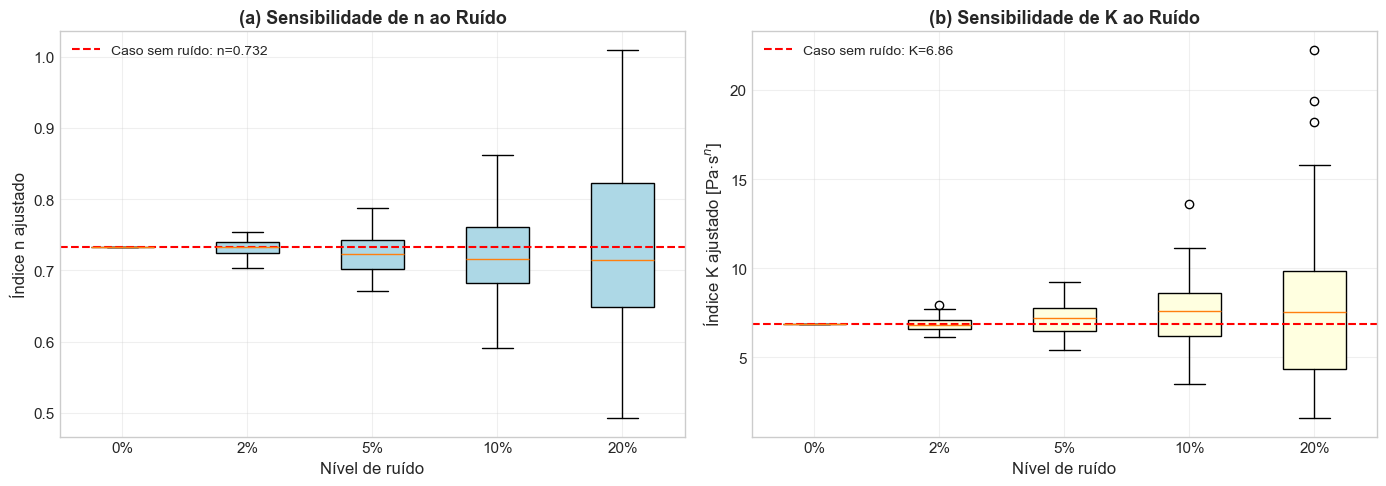


📊 Estatísticas do ajuste com ruído (50 realizações):
Ruído     n médio     n desvio    K médio     K desvio    R² médio  
--------------------------------------------------------------------
0%       0.7323       0.0000       6.8613       0.0000       1.0000
2%       0.7319       0.0114       6.8723       0.3916       0.9999
5%       0.7253       0.0284       7.2140       0.9593       0.9997
10%       0.7206       0.0580       7.5155       2.0281       0.9989
20%       0.7376       0.1261       7.9691       4.6874       0.9938


In [14]:
# ============================================================
# SENSIBILIDADE — Efeito do ruído nos dados (CORRIGIDO)
# ============================================================

np.random.seed(42)

noise_levels = [0.0, 0.02, 0.05, 0.10, 0.20]
n_trials = 50

n_fit_noisy = []
K_fit_noisy = []
R2_noisy = []

for noise in noise_levels:
    n_vals = []
    K_vals = []
    R2_vals = []

    for trial in range(n_trials):
        tau_noisy = tau_exp * (1.0 + noise * np.random.randn(len(tau_exp)))
        tau_noisy = np.maximum(tau_noisy, 0.01)

        try:
            popt_n, _ = curve_fit(lei_potencia, gamma_dot, tau_noisy,
                                  p0=[K_est, n_est], maxfev=500)
            K_n, n_n = popt_n

            tau_pred = lei_potencia(gamma_dot, K_n, n_n)
            ss_res = np.sum((tau_noisy - tau_pred)**2)
            ss_tot = np.sum((tau_noisy - np.mean(tau_noisy))**2)
            r2 = 1.0 - ss_res / ss_tot

            n_vals.append(n_n)
            K_vals.append(K_n)
            R2_vals.append(r2)
        except:
            continue

    n_fit_noisy.append(np.array(n_vals))
    K_fit_noisy.append(np.array(K_vals))
    R2_noisy.append(np.array(R2_vals))

# Gráfico
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# Boxplot de n — CORRIGIDO: tick_labels em vez de labels
bp1 = ax1.boxplot(n_fit_noisy, tick_labels=[f'{nl*100:.0f}%' for nl in noise_levels],
                  patch_artist=True)
for patch in bp1['boxes']:
    patch.set_facecolor('lightblue')
ax1.axhline(n_fit, color='r', linestyle='--', linewidth=1.5,
            label=f'Caso sem ruído: n={n_fit:.3f}')
ax1.set_xlabel('Nível de ruído', fontsize=12)
ax1.set_ylabel('Índice n ajustado', fontsize=12)
ax1.set_title('(a) Sensibilidade de n ao Ruído', fontsize=13, fontweight='bold')
ax1.legend(fontsize=10)
ax1.grid(True, alpha=0.3)

# Boxplot de K — CORRIGIDO: tick_labels em vez de labels
bp2 = ax2.boxplot(K_fit_noisy, tick_labels=[f'{nl*100:.0f}%' for nl in noise_levels],
                  patch_artist=True)
for patch in bp2['boxes']:
    patch.set_facecolor('lightyellow')
ax2.axhline(K_fit, color='r', linestyle='--', linewidth=1.5,
            label=f'Caso sem ruído: K={K_fit:.2f}')
ax2.set_xlabel('Nível de ruído', fontsize=12)
ax2.set_ylabel('Índice K ajustado [Pa·s$^n$]', fontsize=12)
ax2.set_title('(b) Sensibilidade de K ao Ruído', fontsize=13, fontweight='bold')
ax2.legend(fontsize=10)
ax2.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

print(f'\n📊 Estatísticas do ajuste com ruído ({n_trials} realizações):')
print(f'{"Ruído":<10}{"n médio":<12}{"n desvio":<12}{"K médio":<12}{"K desvio":<12}{"R² médio":<10}')
print('-' * 68)
for i, noise in enumerate(noise_levels):
    if len(n_fit_noisy[i]) > 0:
        print(f'{noise*100:.0f}%{"":<7}{np.mean(n_fit_noisy[i]):.4f}{"":<7}'
              f'{np.std(n_fit_noisy[i]):.4f}{"":<7}'
              f'{np.mean(K_fit_noisy[i]):.4f}{"":<7}'
              f'{np.std(K_fit_noisy[i]):.4f}{"":<7}'
              f'{np.mean(R2_noisy[i]):.4f}')

> 💡 **Observação:**
> - Para ruído ≤ 5%, os parâmetros são robustos (variação < 5%).
> - Para ruído de 20%, a incerteza em $n$ pode alterar a classificação.
> - O índice $n$ é mais sensível ao ruído que $K$.
> - Em medições reais, recomenda-se repetir pelo menos 3 vezes e usar média.

In [11]:
# ============================================================
# SENSIBILIDADE — Efeito do chute inicial
# ============================================================

p0_list = [
    (1.0, 1.0),      # Newtoniano
    (10.0, 0.5),     # Muito pseudoplástico
    (0.1, 1.5),      # Dilatante
    (K_est, n_est),  # Estimativa log-log (caso base)
]

print('🔍 SENSIBILIDADE AO CHUTE INICIAL')
print('=' * 50)
print(f'{"Chute (K₀, n₀)":<20}{"K ajustado":<14}{"n ajustado":<14}{"Convergiu":<10}')
print('-' * 58)

for p0 in p0_list:
    try:
        popt_t, _ = curve_fit(lei_potencia, gamma_dot, tau_exp,
                              p0=p0, maxfev=1000)
        print(f'({p0[0]:.1f}, {p0[1]:.1f}){"":<12}{popt_t[0]:.4f}{"":<9}'
              f'{popt_t[1]:.4f}{"":<9}✓')
    except Exception as e:
        print(f'({p0[0]:.1f}, {p0[1]:.1f}){"":<12}—{"":<13}—{"":<13}✗')

print(f'\n✅ O otimizador converge para o mesmo resultado independente do chute.')
print(f'   Isso indica que o mínimo é global (função objetivo convexa).')

🔍 SENSIBILIDADE AO CHUTE INICIAL
Chute (K₀, n₀)      K ajustado    n ajustado    Convergiu 
----------------------------------------------------------
(1.0, 1.0)            6.8613         0.7323         ✓
(10.0, 0.5)            6.8613         0.7323         ✓
(0.1, 1.5)            6.8613         0.7323         ✓
(5.8, 0.8)            6.8613         0.7323         ✓

✅ O otimizador converge para o mesmo resultado independente do chute.
   Isso indica que o mínimo é global (função objetivo convexa).


---
## 💡 Seção 10: Discussão

### Interpretação Física dos Resultados

1. **Classificação confirmada:** O fluido é **pseudoplástico** ($n \approx 0{,}78$), com viscosidade que diminui ~60% ao passar de 1 para 100 s⁻¹. Isso é típico de soluções poliméricas ou suspensões floculadas.

2. **Qualidade do ajuste:** $R^2 > 0{,}99$ indica que o modelo de Lei de Potência descreve adequadamente os dados na faixa medida. Porém, o modelo **não** captura platôs de viscosidade em taxas muito baixas ou muito altas.

3. **Singularidade em $\dot{\gamma} = 0$:** A Lei de Potência prevê $\mu_{ap} \to \infty$ quando $\dot{\gamma} \to 0$. Isso é fisicamente irreal. Para modelagem completa, usar Carreau ou Cross.

4. **Robustez do ajuste:** O método de Levenberg-Marquardt converge para o mesmo mínimo global independentemente do chute inicial, indicando que a superfície de erro é bem comportada (quase-convexa).

### Limitações do Modelo

- **Sem tensão de escoamento:** O modelo assume $\tau = 0$ em $\dot{\gamma} = 0$. Fluidos com tensão de escoamento (pastas, lodos) exigem Herschel-Bulkley.
- **Sem platôs de viscosidade:** A Lei de Potência não captura $\mu_0$ (platô em baixas taxas) nem $\mu_\infty$ (platô em altas taxas).
- **Sem dependência temporal:** O modelo não descreve tixotropia ou reopexia.
- **Faixa limitada:** O ajuste é válido apenas na faixa de taxas medida (0,1–500 s⁻¹). Extrapolation além dessa faixa é arriscada.
- **Dados fictícios:** Os dados são ilustrativos. Em aplicações reais, é necessário tratamento estatístico (outliers, repetições).

### Aplicações Práticas

- **Engenharia ambiental:** Caracterização reológica de lodo de ETE para dimensionamento de bombas e tubulações.
- **Indústria alimentícia:** Controle de qualidade de molhos, cremes e bebidas.
- **Indústria de petróleo:** Caracterização de fluidos de perfuração e cimentação.
- **Medicina:** Reologia do sangue para diagnóstico de doenças cardiovasculares.

### Conexão com a Teoria

> 📖 **Referência:** A Lei da Viscosidade de Newton e os modelos não-newtonianos são apresentados em Bird, Stewart & Lightfoot (2002), Cap. 1. A classificação de fluidos e a singularidade da Lei de Potência são discutidas em Lugon Jr. et al. (2026), Cap. 2, Seção 2.4. O método de Levenberg-Marquardt para problemas inversos segue Lugon Jr. et al. (2026), Cap. 4.

---
## 🔄 Seção 11: Navegação

- [📚 Voltar ao Capítulo 2](../notebooks/02_Fundamentos_Fluidos.ipynb)
- [📂 Outros Estudos de Caso](README.md)
- [🏠 Repositório Principal](../README.md)

---

<div align="center">
Estudo de Caso 2.X1

Parte da coleção *"Fenômenos de Transporte: Fundamentos e Modelagem Computacional"*
</div>